# Benchmarking translation methods: scButterfly, BABEL and scPair

`epi.translate.benchmark` compares translation methods on the metrics of the scTranslation benchmark. This notebook trains two methods on the same 10x Multiome PBMC split:
- **scButterfly** (Cao *et al.*, 2024), a dual-aligned VAE with adversarial discriminators;
- **BABEL** (Wu *et al.*, 2021), a shared-latent autoencoder with negative-binomial RNA and per-chromosome ATAC decoders;
- **scPair** (Hu *et al.*), one supervised predictor per direction, with Bernoulli (ATAC) and zero-inflated negative-binomial (RNA) decoders.

A kNN baseline is included as well. All are compared in both directions. For a walk-through of a single method, see the scButterfly tutorial.

The methods predict in **different spaces**, so the comparison is set up accordingly (see *Benchmark* below).

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import epione as epi

sc.settings.verbosity = 0
rna, atac = epi.datasets.pbmc10k_multiome(os.environ.get("EPIONE_PBMC10K_DIR"))

## Each method's preprocessing

`prepare(..., method=...)` returns the input each method expects. Both use the same 3,000 highly variable genes and the same filtered peaks.

| | scButterfly | BABEL | scPair |
|---|---|---|---|
| RNA input | log-normalised expression | raw counts; BABEL size-normalises, log-transforms and standardises them internally | raw counts |
| ATAC input | TF-IDF, scaled to [0, 1] | binary | peak counts, binarised internally |

In [2]:
rna_s, atac_s = epi.translate.prepare(rna, atac)                    # scButterfly
rna_b, atac_b = epi.translate.prepare(rna, atac, method="babel")    # BABEL
rna_p, atac_p = epi.translate.prepare(rna, atac, method="scpair")   # scPair
assert list(rna_s.var_names) == list(rna_b.var_names) and list(atac_s.var_names) == list(atac_b.var_names)

from sklearn.model_selection import StratifiedKFold, train_test_split
y = rna_s.obs["cell_type"].astype(str).to_numpy()
rest, test = next(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(y, y))
train, valid = train_test_split(rest, test_size=0.1, stratify=y[rest], random_state=0)
print(f"train {len(train)}, validation {len(valid)}, test {len(test)}")

train 6933, validation 771, test 1927


## Train both methods

In [3]:
import time

t0 = time.time()
butterfly = epi.translate.fit(rna_s, atac_s, method="scbutterfly", train_idx=train, val_idx=valid, seed=0)
t_butterfly = time.time() - t0
t0 = time.time()
babel = epi.translate.fit(rna_b, atac_b, method="babel", train_idx=train, val_idx=valid, seed=0)
t_babel = time.time() - t0
t0 = time.time()
scpair = epi.translate.fit(rna_p, atac_p, method="scpair", train_idx=train, val_idx=valid, seed=0)
t_scpair = time.time() - t0
print(f"scButterfly {t_butterfly:.0f} s, BABEL {t_babel:.0f} s, scPair {t_scpair:.0f} s")

scButterfly 1471 s, BABEL 58 s, scPair 193 s


In [4]:
pred = {
    "rna2atac": {"scButterfly": butterfly.predict(rna_s[test]), "BABEL": babel.predict(rna_b[test]),
                 "scPair": scpair.predict(rna_p[test])},
    "atac2rna": {"scButterfly": butterfly.predict(atac_s[test]), "BABEL": babel.predict(atac_b[test]),
                 "scPair": scpair.predict(atac_p[test])},
}

A kNN baseline averages the target profiles of the 10 training cells nearest in the source modality. It uses scButterfly's representation and is scored in that space.

In [5]:
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors
import scipy.sparse as sp

def knn_translate(src, dst, k=10):
    svd = TruncatedSVD(50, random_state=0).fit(src.X[train])
    nn = NearestNeighbors(n_neighbors=k).fit(svd.transform(src.X[train]))
    idx = nn.kneighbors(svd.transform(src.X[test]), return_distance=False)
    Y = sp.csr_matrix(dst.X[train])
    out = np.vstack([np.asarray(Y[i].mean(axis=0)).ravel() for i in idx]).astype(np.float32)
    return sc.AnnData(out, obs=dst.obs.iloc[test].copy(), var=dst.var[[]].copy())

pred["rna2atac"]["kNN"] = knn_translate(rna_s, atac_s)
pred["atac2rna"]["kNN"] = knn_translate(atac_s, rna_s)

## Benchmark

Each method is scored against **its own target space**:

| method | RNA → ATAC truth | ATAC → RNA truth |
|---|---|---|
| scButterfly and kNN | the TF-IDF-scaled measured accessibility | the log-normalised measured expression |
| BABEL | the binary measured accessibility | the measured counts, size-normalised to the test cells' median (`epi.translate.size_normalize`) |
| scPair | the binary measured accessibility (its training target) | the measured expression proportions, i.e. counts divided by each cell's total (scPair predicts proportions) |

`benchmark` accepts this as `{task: {method: truth}}`.
- **Comparable:** the clustering, correlation (PCC, SPCC, CORR), AUROC/AUPRC and distribution (MMD, iLISI) metrics each measure how well a method reproduces its target, so they can be compared.
- **Not comparable:** errors in different units, so **MSE and MAE are left out**.

In [6]:
truth = {
    "rna2atac": {"scButterfly": atac_s[test], "kNN": atac_s[test], "BABEL": atac_b[test],
                 "scPair": atac_b[test]},   # binary peaks, scPair's training target
    "atac2rna": {"scButterfly": rna_s[test], "kNN": rna_s[test], "BABEL": epi.translate.size_normalize(rna_b[test]),
                 "scPair": epi.translate.size_normalize(rna_p[test], target_sum=1.0)},
}
res = epi.translate.benchmark(pred, truth, labels="cell_type", exclude=("MSE", "MAE"))
summary = epi.translate.summarize(res)
summary.round(3)

metric                                                   \
                        ARI    AMI    NMI    HOM    PCC   SPCC   CORR    MMD   
task     method                                                                
atac2rna scButterfly  0.433  0.743  0.752  0.847  0.764  0.385  0.256  0.104   
         kNN          0.432  0.737  0.748  0.846  0.744  0.394  0.183  0.074   
         scPair       0.363  0.630  0.640  0.676  0.969  0.423  0.172  0.596   
         BABEL        0.271  0.569  0.586  0.675  0.960  0.349  0.186  0.599   
rna2atac scButterfly  0.429  0.748  0.758  0.858  0.309  0.346  0.145  0.044   
         scPair       0.258  0.554  0.571  0.648  0.512  0.355  0.111  0.187   
         kNN          0.446  0.729  0.740  0.823  0.226  0.334  0.082  0.012   
         BABEL        0.359  0.613  0.625  0.682  0.492  0.337  0.126  1.441   

                                               score                          \
                      iLISI  AUROC  AUPRC clustering regression distribution   
task     method                                                                
atac2rna scButterfly  0.528  0.910  0.568      1.000      0.524        0.897   
         kNN          0.584  0.859  0.515      0.982      0.244        1.000   
         scPair       0.283  0.872  0.535      0.312      0.667        0.108   
         BABEL        0.202  0.911  0.527      0.000      0.375        0.000   
rna2atac scButterfly  0.397  0.892  0.402      0.977      0.619        0.801   
         scPair       0.403  0.896  0.441      0.000      0.822        0.756   
         kNN          0.636  0.807  0.234      0.910      0.000        1.000   
         BABEL        0.000  0.877  0.442      0.322      0.592        0.000   

                                             
                     classification overall  
task     method                              
atac2rna scButterfly          0.998   0.855  
         kNN                  0.000   0.556  
         scPair               0.319   0.351  
         BABEL                0.617   0.248  
rna2atac scButterfly          0.883   0.820  
         scPair               0.998   0.644  
         kNN                  0.000   0.478  
         BABEL                0.893   0.452

In the plots, circles are per-metric scores min-max scaled across the methods in each task (large and yellow is best). Bars are the category and overall means of those scaled scores.

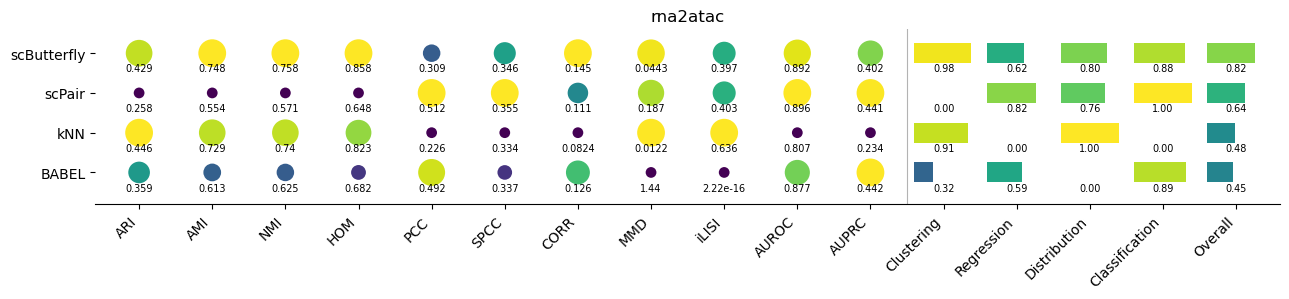

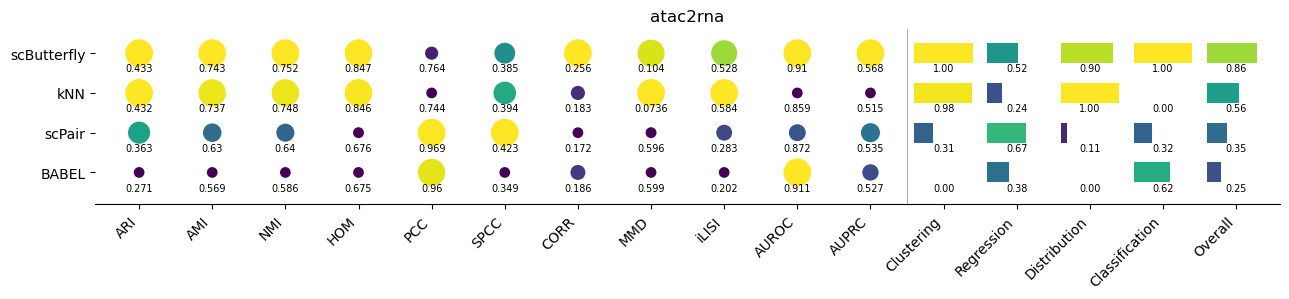

In [7]:
for task in ["rna2atac", "atac2rna"]:
    epi.translate.plot_benchmark(res, task)

In [8]:
s = summary["metric"]
for task in ["rna2atac", "atac2rna"]:
    for other in ["BABEL", "scPair"]:
        a, b = s.loc[(task, "scButterfly")], s.loc[(task, other)]
        wins = [m for m in s.columns if np.isfinite(a[m]) and np.isfinite(b[m])
                and ((b[m] > a[m]) if epi.translate.METRICS[m][1] else (b[m] < a[m]))]
        print(f"{task}: {other} ahead of scButterfly on {', '.join(wins) or 'nothing'}")

rna2atac: BABEL ahead of scButterfly on PCC, AUPRC
rna2atac: scPair ahead of scButterfly on PCC, SPCC, iLISI, AUROC, AUPRC
atac2rna: BABEL ahead of scButterfly on PCC, AUROC
atac2rna: scPair ahead of scButterfly on PCC, SPCC


## Caveats

- **One split, one seed.** This is a single split with seed 0. The validation runs behind each method used 3 seeds; seed-to-seed spread in Leiden ARI and iLISI is several points.
- **Different truth spaces.** The targets differ (binary vs TF-IDF ATAC, counts vs log expression), so a metric can favour the method whose target is easier to match. The comparison says how well each method reproduces its own target. It doesn't say which predicted profile is more biologically correct.
- **Validation status.** How each implementation compares with its reference:

| method | validation against its reference implementation (3 seeds, `tests/parity/translate_*/MANIFEST.md`) |
|---|---|
| scButterfly | **passes**: 23 / 23 metric × direction pairs within the seed spread of scTranslation's scButterfly |
| scPair | **passes**: 23 / 23 |
| BABEL | **does not pass**: 6 / 23. Epione's BABEL is a clean-room reimplementation from the paper (the reference code has no license). Inputs, targets and metrics were verified identical. scTranslation's BABEL drops the per-chromosome ATAC layers, which plausibly explains why Epione's RNA → ATAC is better (PCC 0.50 vs 0.37). Epione's ATAC → RNA clustering is worse (ARI 0.28 vs 0.39), and that remains unexplained |

So the BABEL numbers here describe Epione's implementation of the paper. They are not a reproduction of scTranslation's BABEL results.